# Phân tích dữ liệu Melbourne Housing Snapshot

**Mục tiêu:** xây dựng một quy trình DA có thể chạy từ đầu đến cuối bằng Pandas, NumPy, Matplotlib và Seaborn; sau đó có thể mở rộng thêm phân tích hoặc mô hình Regression.

**Nguồn:** [Melbourne Housing Snapshot — Kaggle](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot). Trang dữ liệu mô tả đây là snapshot của dữ liệu do Tony Pino tạo, thu thập bằng phương pháp cào dữ liệu web (web scraping) từ các tin đăng công khai qua https://www.domain.com.au; notebook này không tự cào dữ liệu mà đọc tệp CSV đã tải từ Kaggle. Giấy phép được ghi trên Kaggle là **CC BY-NC-SA 4.0**; cần giữ ghi công và tuân thủ điều kiện giấy phép khi chia sẻ hoặc biến đổi dữ liệu.

**Phạm vi:** bộ dữ liệu lịch sử ở Melbourne, Australia, không đại diện cho giá nhà hiện tại hoặc thị trường Việt Nam.

**Luồng thực hiện:** Dataset → Data Cleaning → Analysis → Visualization 

## 0. Chuẩn bị môi trường

Cài thư viện một lần trong Terminal của VS Code (nếu chưa có):

```powershell
python -m pip install pandas numpy matplotlib seaborn jupyter
```

Đặt `melb_data.csv` ở thư mục `data/` cạnh notebook theo cấu trúc dự án, hoặc điều chỉnh `DATA_PATH` ở cell bên dưới.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "melb_data.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Thư mục làm việc:", PROJECT_DIR)
print("Đường dẫn dataset:", DATA_PATH)

Thư mục làm việc: d:\Code\Python\2611COMP1804-LapTrinhPython-DoAnGK
Đường dẫn dataset: d:\Code\Python\2611COMP1804-LapTrinhPython-DoAnGK\data\melb_data.csv


## 1. Đọc dữ liệu bằng Pandas

Không chỉnh sửa dữ liệu gốc trực tiếp. `df_raw` được giữ làm bản tham chiếu để đối chiếu trước/sau làm sạch.

In [ ]:
if not DATA_PATH.exists():
    # Cho phép đặt CSV ngay cạnh notebook nếu không dùng thư mục data/
    alternative_path = PROJECT_DIR / "melb_data.csv"
    if alternative_path.exists():
        DATA_PATH = alternative_path
    else:
        raise FileNotFoundError(
            f"Không tìm thấy {DATA_PATH}. Hãy đặt melb_data.csv trong data/ "
            "hoặc cùng thư mục với notebook, rồi chạy lại cell này."
        )

# Hiển thị 5 dòng đầu tiên của dataset
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(f"Dataset có {df_raw.shape[0]:,} dòng và {df_raw.shape[1]} cột.")
display(df_raw.head())

Dataset có 13,580 dòng và 21 cột.


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## 2. Tổng quan và mô tả thuộc tính

Dataset có các biến về khu vực (`Suburb`, `Regionname`, `CouncilArea`), đặc điểm bất động sản (`Rooms`, `Type`, `Bathroom`, `Car`, `Landsize`, `BuildingArea`, `YearBuilt`) và giá (`Price`).

In [ ]:
#Hiển thị thông tin cơ bản về dataset
print("Kích thước:", df_raw.shape)
print("Số dòng trùng hoàn toàn:", df_raw.duplicated().sum())
print("Số thuộc tính:", df_raw.shape[1])

#Từ điển data
data_dictionary = pd.DataFrame([
    ("Suburb", "Khu vực nhỏ/suburb"),
    ("Address", "Địa chỉ bất động sản"),
    ("Rooms", "Số phòng"),
    ("Type", "Loại bất động sản: h, u, t"),
    ("Price", "Giá bán, AUD; biến quan tâm chính"),
    ("Method", "Mã phương thức/kết quả bán"),
    ("SellerG", "Đơn vị/môi giới bán"),
    ("Date", "Ngày giao dịch/bán theo dataset"),
    ("Distance", "Khoảng cách đến CBD, km"),
    ("Postcode", "Mã bưu chính"),
    ("Bedroom2", "Số phòng ngủ theo nguồn dữ liệu"),
    ("Bathroom", "Số phòng tắm"),
    ("Car", "Số chỗ đậu xe"),
    ("Landsize", "Diện tích đất"),
    ("BuildingArea", "Diện tích xây dựng"),
    ("YearBuilt", "Năm xây dựng"),
    ("CouncilArea", "Khu vực chính quyền địa phương"),
    ("Lattitude", "Vĩ độ; tên cột theo file gốc"),
    ("Longtitude", "Kinh độ; tên cột theo file gốc"),
    ("Regionname", "Vùng địa lý lớn"),
    ("Propertycount", "Số bất động sản tại suburb"),
], columns=["Column", "Mô tả"])
display(data_dictionary)

Kích thước: (13580, 21)
Số dòng trùng hoàn toàn: 0
Số thuộc tính: 21


,Column,Mô tả
0,Suburb,Khu vực nhỏ/suburb
1,Address,Địa chỉ bất động sản
2,Rooms,Số phòng
3,Type,"Loại bất động sản: h, u, t"
4,Price,"Giá bán, AUD; biến quan tâm chính"
5,Method,Mã phương thức/kết quả bán
6,SellerG,Đơn vị/môi giới bán
7,Date,Ngày giao dịch/bán theo dataset
8,Distance,"Khoảng cách đến CBD, km"
9,Postcode,Mã bưu chính


## 3. Kiểm tra dữ liệu

Kiểm tra kiểu dữ liệu bằng `dtypes`, `info()` và chuyển `Date` sang datetime ở bước làm sạch. Các cột mã như `Postcode` có thể được cân nhắc xem là biến phân loại trong phân tích, dù file gốc biểu diễn chúng dưới dạng số.

In [ ]:
#Đọc data
dtype_report = pd.DataFrame({
    "Kiểu data": df_raw.dtypes.astype(str),
    "Số lượng không null": df_raw.notna().sum(),
    "Số giá trị duy nhất": df_raw.nunique(dropna=True),
})
display(dtype_report)

#Giá cao nhất/thấp nhất
print(f"Giá cao nhất: ${df_raw['Price'].max():,}")
print(f"Giá thấp nhất: ${df_raw['Price'].min():,}")

#Giá trung vị/trung bình
print(f"Giá trung vị: ${df_raw['Price'].median():,}")
print(f"Giá trung bình: ${df_raw['Price'].mean():,.2f}")

#Cơ cấu nhà theo loại
type_counts = df_raw['Type'].value_counts()
print("Cơ cấu nhà theo loại:")
for type_name, count in type_counts.items():
    print(f"  {type_name}: {count} - {count / len(df_raw) * 100:.2f}%")

#Cơ cấu % nhà theo vùng 
print("Cơ cấu nhà theo vùng:")
for region_name, count in region_counts.items():
    print(f"  {region_name}: {count} - {count / len(df_raw) * 100:.2f}%")

#Số cột các loại giá trị
print("Số cột các loại giá trị:")
for dtype, count in df_raw.dtypes.value_counts().items():
    print(f"  {dtype}: {count}")

#Tổng số dòng trùng, dòng có giá trị null và dòng có giá Price không hợp lệ
duplicate_rows = df_raw.duplicated().sum()
null_rows = df_raw.isnull().any(axis=1).sum()
invalid_price_rows = df_raw[df_raw['Price'].isnull() | (df_raw['Price'] ≤  0)].shape[0]
print(f"Tổng số dòng trùng: {duplicate_rows}")
print(f"Tổng số dòng có giá trị null: {null_rows}")
print(f"Tổng số dòng có giá Price không hợp lệ: {invalid_price_rows}")

,Kiểu data,Số lượng không null,Số giá trị duy nhất
Suburb,str,13580,314
Address,str,13580,13378
Rooms,int64,13580,9
Type,str,13580,3
Price,float64,13580,2204
Method,str,13580,5
SellerG,str,13580,268
Date,str,13580,58
Distance,float64,13580,202
Postcode,float64,13580,198


Giá cao nhất: $9,000,000.0
Giá thấp nhất: $85,000.0
Giá trung vị: $903,000.0
Giá trung bình: $1,075,684.08
Cơ cấu nhà theo loại:
  h: 9449 - 69.58%
  u: 3017 - 22.22%
  t: 1114 - 8.20%
Cơ cấu nhà theo vùng:
  Southern Metropolitan: 4695 - 34.57%
  Northern Metropolitan: 3890 - 28.65%
  Western Metropolitan: 2948 - 21.71%
  Eastern Metropolitan: 1471 - 10.83%
  South-Eastern Metropolitan: 450 - 3.31%
  Eastern Victoria: 53 - 0.39%
  Northern Victoria: 41 - 0.30%
  Western Victoria: 32 - 0.24%
Số cột các loại giá trị:
  float64: 12
  str: 8
  int64: 1
Tổng số dòng trùng: 0
Tổng số dòng có giá trị null: 7384
Tổng số dòng có giá Price không hợp lệ: 0


## 4. Phát hiện dữ liệu thiếu, trùng và giá trị đáng ngờ

In [37]:
#Báo cáo thiếu dữ liệu
missing_report = pd.DataFrame({
    "Số ô thiếu": df_raw.isna().sum(),
    "Tỷ lệ thiếu (%)": (df_raw.isna().mean() * 100).round(2),
    "Giá trị duy nhất": df_raw.nunique(dropna=True),
}).sort_values("Tỷ lệ thiếu (%)", ascending=False)
print("Báo cáo thiếu dữ liệu:")
display(missing_report)
print("Số dòng trùng hoàn toàn:", int(df_raw.duplicated().sum()))

#Kiểm tra giá trị bất thường 
invalid_report = pd.Series({
    "Price ≤  0": (df_raw["Price"] <=  0).sum(),
    "Rooms ≤  0": (df_raw["Rooms"] <=  0).sum(),
    "Distance < 0": (df_raw["Distance"] < 0).sum(),
    "Landsize < 0": (df_raw["Landsize"] < 0).sum(),
    "BuildingArea ≤  0": (df_raw["BuildingArea"] <=  0).sum(),
    "YearBuilt < 1700": (df_raw["YearBuilt"] < 1700).sum(),
    "Landsize = 0": (df_raw["Landsize"] == 0).sum(),
    "Landsize > 10000": (df_raw["Landsize"] > 10_000).sum(),
    "BuildingArea > 1000": (df_raw["BuildingArea"] > 1_000).sum(),
    "Bathroom = 0": (df_raw["Bathroom"] == 0).sum(),
    "YearBuilt ≥ 2017": (df_raw["YearBuilt"] >= 2017).sum(),
    "Distance = 0": (df_raw["Distance"] == 0).sum(),
    "Rooms ≥ 7": (df_raw["Rooms"] >= 7).sum(),
    "Longtitude & Lattitude out of range": ((df_raw["Longtitude"] < 140) | (df_raw["Longtitude"] > 150) | (df_raw["Lattitude"] < -40) | (df_raw["Lattitude"] > -30)).sum()
}, name="Số bản ghi")
print("Các quy tắc kiểm tra tính hợp lệ:")
display(invalid_report.to_frame())


Báo cáo thiếu dữ liệu:


,Số ô thiếu,Tỷ lệ thiếu (%),Giá trị duy nhất
BuildingArea,6450,47.50,602
YearBuilt,5375,39.58,144
CouncilArea,1369,10.08,33
Car,62,0.46,11
Suburb,0,0.00,314
Price,0,0.00,2204
Type,0,0.00,3
Rooms,0,0.00,9
Address,0,0.00,13378
Distance,0,0.00,202


Số dòng trùng hoàn toàn: 0
Các quy tắc kiểm tra tính hợp lệ:


,Số bản ghi
Price ≤ 0,0
Rooms ≤ 0,0
Distance < 0,0
Landsize < 0,0
BuildingArea ≤ 0,17
YearBuilt < 1700,1
Landsize = 0,1939
Landsize > 10000,26
BuildingArea > 1000,8
Bathroom = 0,34


## 5. Làm sạch dữ liệu 

1. Sao chép dữ liệu gốc và loại dòng trùng hoàn toàn.
2. Chuyển `Date` sang datetime với `dayfirst=True`.
3. Ép các cột số về kiểu số; giá trị không chuyển được thành số sẽ thành thiếu.
4. Chuyển các giá trị rõ ràng không hợp lý thành `NaN`: `Price ≤  0`, `Rooms ≤  0`, `Distance < 0`, `Landsize < 0`, `BuildingArea ≤  0`, `YearBuilt < 1700` và tọa độ ngoài vùng kiểm tra rộng của Melbourne.
5. Loại ngoại lai: đặt `Landsize > 10.000` m², `BuildingArea > 1.000` m² và `Bathroom == 0` thành `NaN`. Giao dịch và giá được giữ nguyên, chỉ bỏ giá trị đáng ngờ. Giữ `Landsize == 0` vì nghĩa là không có đất riêng (chủ yếu là căn hộ), không phải lỗi.
6. Loại dòng không có giá bán hợp lệ vì các phân tích trọng tâm so sánh giá.
7. Điền thiếu `CouncilArea` thành `Unknown`; không tự điền trung vị cho `BuildingArea` và `YearBuilt` vì tỷ lệ thiếu cao và phép điền có thể làm méo thống kê mô tả.
8. Thêm `SaleYear`/`SaleMonth` phục vụ phân tích thời gian và cờ chỉ ra giá trị vốn đã thiếu trong một số cột.

Giá bán cao không bị coi là ngoại lai để loại bỏ: đó là các giao dịch có thể có thật, nên chỉ được đánh dấu bằng IQR ở bước 4.

Các ngưỡng hợp lệ là quy tắc phân tích cần được mô tả trong báo cáo, không phải chân lý tuyệt đối của dữ liệu bất động sản.

In [ ]:
def clean_data(df_input: pd.DataFrame) -> pd.DataFrame:
    data = df_input.copy().drop_duplicates().copy()

    if "Date" in data.columns:
        data["Date"] = pd.to_datetime(data["Date"], dayfirst=True, errors="coerce")

    numeric_cols = [
        "Rooms", "Price", "Distance", "Postcode", "Bedroom2", "Bathroom",
        "Car", "Landsize", "BuildingArea", "YearBuilt", "Lattitude",
        "Longtitude", "Propertycount"
    ]
    for col in numeric_cols:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors="coerce")

    # Cờ này phản ánh thiếu trước khi áp dụng quy tắc giá trị không hợp lý.
    for col in ["Car", "BuildingArea", "YearBuilt", "CouncilArea"]:
        if col in data.columns:
            data[f"{col}_was_missing"] = data[col].isna().astype("int8")

    data.loc[data["Price"] ≤  0, "Price"] = np.nan
    data.loc[data["Rooms"] ≤  0, "Rooms"] = np.nan
    data.loc[data["Distance"] < 0, "Distance"] = np.nan
    data.loc[data["Landsize"] < 0, "Landsize"] = np.nan
    data.loc[data["BuildingArea"] ≤  0, "BuildingArea"] = np.nan
    data.loc[data["YearBuilt"] < 1700, "YearBuilt"] = np.nan
    # Ngoại lai: bỏ giá trị diện tích phi thực tế và 0 phòng tắm, giữ giao dịch.
    data.loc[data["Landsize"] > 10_000, "Landsize"] = np.nan
    data.loc[data["BuildingArea"] > 1_000, "BuildingArea"] = np.nan
    data.loc[data["Bathroom"] == 0, "Bathroom"] = np.nan
    data.loc[~data["Lattitude"].between(-39.5, -36.0), "Lattitude"] = np.nan
    data.loc[~data["Longtitude"].between(142.0, 147.0), "Longtitude"] = np.nan

    data = data.dropna(subset=["Price"])
    data["CouncilArea"] = data["CouncilArea"].fillna("Unknown")

    data["SaleYear"] = data["Date"].dt.year
    data["SaleMonth"] = data["Date"].dt.month
    return data.reset_index(drop=True)


df_clean = clean_data(df_raw)
print("Kích thước ban đầu:", df_raw.shape)
print("Kích thước sau làm sạch:", df_clean.shape)
print("Dòng trùng còn lại:", df_clean.duplicated().sum())
print("Ngày không parse được:", df_clean["Date"].isna().sum())
display(df_clean.head())

Kích thước ban đầu: (13580, 21)
Kích thước sau làm sạch: (13580, 27)
Dòng trùng còn lại: 0
Ngày không parse được: 0


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Car_was_missing,BuildingArea_was_missing,YearBuilt_was_missing,CouncilArea_was_missing,SaleYear,SaleMonth
0,Abbotsford,85 Turner St,2.0,h,1480000.0,S,Biggin,2016-12-03,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0,0,1,1,0,2016,12
1,Abbotsford,25 Bloomburg St,2.0,h,1035000.0,S,Biggin,2016-02-04,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0,0,0,0,0,2016,2
2,Abbotsford,5 Charles St,3.0,h,1465000.0,SP,Biggin,2017-03-04,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0,0,0,0,0,2017,3
3,Abbotsford,40 Federation La,3.0,h,850000.0,PI,Biggin,2017-03-04,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0,0,1,1,0,2017,3
4,Abbotsford,55a Park St,4.0,h,1600000.0,VB,Nelson,2016-06-04,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0,0,0,0,0,2016,6


### 5.1. Đối chiếu dữ liệu sau làm sạch

Đánh giá xem dữ liệu còn thiếu ở đâu. Giữ `NaN` trong các biến có tỷ lệ thiếu lớn là một quyết định có chủ đích; các phân tích liên quan đến biến đó sẽ dùng các dòng có dữ liệu quan sát được và phải nêu rõ khi diễn giải.

In [9]:
clean_missing_report = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_pct": (df_clean.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
display(clean_missing_report.head(12))

# Lưu bản sạch để có thể dùng lại ở các phần sau.
clean_path = OUTPUT_DIR / "melb_data_clean.csv"
df_clean.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("Đã lưu:", clean_path)

,missing_count,missing_pct
BuildingArea,6475,47.68
YearBuilt,5376,39.59
Car,62,0.46
Bathroom,34,0.25
Landsize,26,0.19
Method,0,0.00
Price,0,0.00
Type,0,0.00
Suburb,0,0.00
Address,0,0.00


Đã lưu: /home/claude/2611comp1804-laptrinhpython-doangk/outputs/melb_data_clean.csv


## 6. Phân tích/thống kê 1 — Thống kê mô tả giá bán

Dùng `describe()` để xem trung bình, trung vị, độ lệch chuẩn, các phân vị và khoảng giá. So sánh mean với median giúp nhận diện phân phối lệch.

In [10]:
price_summary = df_clean["Price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("Price_AUD")
display(price_summary)
print("Skewness của Price:", round(df_clean["Price"].skew(), 3))
print("Mean:", f"{df_clean['Price'].mean():,.0f} AUD")
print("Median:", f"{df_clean['Price'].median():,.0f} AUD")

,Price_AUD
count,1.358000e+04
mean,1.075684e+06
std,6.393107e+05
min,8.500000e+04
1%,3.000000e+05
5%,4.050000e+05
25%,6.500000e+05
50%,9.030000e+05
75%,1.330000e+06
95%,2.290050e+06


Skewness của Price: 2.24
Mean: 1,075,684 AUD
Median: 903,000 AUD


## 7. Phân tích/thống kê 2 — Giá theo loại bất động sản (`groupby`)

In [11]:
price_by_type = df_clean.groupby("Type")["Price"].agg(
    count="count", mean="mean", median="median", min="min", max="max"
).sort_values("median", ascending=False)
display(price_by_type.style.format({"mean": "{:,.0f}", "median": "{:,.0f}", "min": "{:,.0f}", "max": "{:,.0f}"}))

,count,mean,median,min,max
Type,,,,,
h,9449,"1,242,665","1,080,000","131,000","9,000,000"
t,1114,"933,735","846,750","300,000","3,475,000"
u,3017,"605,127","560,000","85,000","3,625,000"


## 8. Phân tích/thống kê 3 — Giá theo vùng

Sắp xếp khu vực theo giá trung vị. Khu vực có ít quan sát sẽ cần được diễn giải thận trọng; bảng giữ lại cả số lượng để người đọc biết cỡ mẫu.

In [12]:
price_by_region = df_clean.groupby("Regionname")["Price"].agg(
    count="count", mean="mean", median="median"
).sort_values("median", ascending=False)
display(price_by_region.style.format({"mean": "{:,.0f}", "median": "{:,.0f}"}))

,count,mean,median
Regionname,,,
Southern Metropolitan,4695,"1,372,963","1,250,000"
Eastern Metropolitan,1471,"1,104,080","1,010,000"
South-Eastern Metropolitan,450,"922,944","850,000"
Northern Metropolitan,3890,"898,171","806,250"
Western Metropolitan,2948,"866,421","793,000"
Eastern Victoria,53,"699,981","670,000"
Northern Victoria,41,"594,829","540,000"
Western Victoria,32,"397,523","400,000"


## 9. Phân tích/thống kê 4 — Giá theo số phòng

Lọc các nhóm số phòng có ít nhất 20 bản ghi để so sánh ổn định hơn. Việc lọc này chỉ áp dụng cho bảng so sánh, không xóa các dòng đó khỏi dataset tổng thể.

In [ ]:
price_by_rooms = df_clean.groupby("Rooms")["Price"].agg(
    count="count", mean="mean", median="median"
).sort_index()
display(price_by_rooms)
display(price_by_rooms.loc[price_by_rooms["count"] ≥ 20])

,count,mean,median
Rooms,,,
1.0,681,4.338245e+05,385000.0
2.0,3648,7.750812e+05,690000.0
3.0,5881,1.076081e+06,950000.0
4.0,2688,1.445282e+06,1285000.0
5.0,596,1.870260e+06,1660000.0
6.0,67,1.849366e+06,1800000.0
7.0,10,1.920700e+06,1496000.0
8.0,8,1.602750e+06,1515000.0
10.0,1,9.000000e+05,900000.0


,count,mean,median
Rooms,,,
1.0,681,4.338245e+05,385000.0
2.0,3648,7.750812e+05,690000.0
3.0,5881,1.076081e+06,950000.0
4.0,2688,1.445282e+06,1285000.0
5.0,596,1.870260e+06,1660000.0
6.0,67,1.849366e+06,1800000.0


## 10. Phân tích/thống kê 5 — Các suburb có giá trung vị cao

Chỉ xét suburb có từ 30 bản ghi trở lên để giảm ảnh hưởng của nhóm có số lượng quá ít. Đây là so sánh trong snapshot lịch sử, không phải bảng xếp hạng giá hiện tại.

In [ ]:
top_suburbs = df_clean.groupby("Suburb")["Price"].agg(
    count="count", median="median", mean="mean"
).query("count ≥ 30").sort_values("median", ascending=False).head(10)
display(top_suburbs.style.format({"median": "{:,.0f}", "mean": "{:,.0f}"}))

,count,median,mean
Suburb,,,
Albert Park,69,"1,900,000","1,941,355"
Canterbury,54,"1,890,000","2,180,241"
Middle Park,34,"1,880,000","2,082,529"
Balwyn,107,"1,850,000","1,869,879"
Brighton,186,"1,773,500","1,930,158"
Kew East,49,"1,750,000","1,694,163"
Balwyn North,171,"1,739,000","1,793,405"
Camberwell,132,"1,695,000","1,739,350"
Glen Iris,195,"1,660,000","1,624,844"


## 11. Phân tích/thống kê 6 — Tương quan giữa các biến số

Tương quan Pearson mô tả mức độ liên hệ tuyến tính. Nó không chứng minh quan hệ nhân quả và có thể bị ảnh hưởng bởi giá ngoại lệ, phân khúc bất động sản hoặc sự khác biệt giữa các khu vực.

In [15]:
corr_cols = ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Distance", "Landsize", "BuildingArea", "YearBuilt", "Propertycount"]
correlation = df_clean[corr_cols].corr(numeric_only=True)
display(correlation.round(3))
print("corr(Price, Rooms) =", round(df_clean["Price"].corr(df_clean["Rooms"]), 3))
print("corr(Price, Distance) =", round(df_clean["Price"].corr(df_clean["Distance"]), 3))

,Price,Rooms,Bedroom2,Bathroom,Car,Distance,Landsize,BuildingArea,YearBuilt,Propertycount
Price,1.000,0.497,0.476,0.469,0.239,-0.163,0.132,0.556,-0.332,-0.042
Rooms,0.497,1.000,0.944,0.594,0.408,0.294,0.189,0.644,-0.067,-0.082
Bedroom2,0.476,0.944,1.000,0.585,0.405,0.296,0.185,0.630,-0.055,-0.081
Bathroom,0.469,0.594,0.585,1.000,0.316,0.125,0.109,0.588,0.155,-0.052
Car,0.239,0.408,0.405,0.316,1.000,0.263,0.186,0.358,0.114,-0.024
Distance,-0.163,0.294,0.296,0.125,0.263,1.000,0.152,0.187,0.255,-0.055
Landsize,0.132,0.189,0.185,0.109,0.186,0.152,1.000,0.172,0.019,-0.019
BuildingArea,0.556,0.644,0.630,0.588,0.358,0.187,0.172,1.000,0.035,-0.069
YearBuilt,-0.332,-0.067,-0.055,0.155,0.114,0.255,0.019,0.035,1.000,0.010
Propertycount,-0.042,-0.082,-0.081,-0.052,-0.024,-0.055,-0.019,-0.069,0.010,1.000


corr(Price, Rooms) = 0.497
corr(Price, Distance) = -0.163


## 12. Trực quan hóa 1 — Histogram giá bán

Biểu đồ histogram cho biết phần lớn giao dịch nằm ở khoảng giá nào và giúp nhìn sơ bộ độ lệch của phân phối.

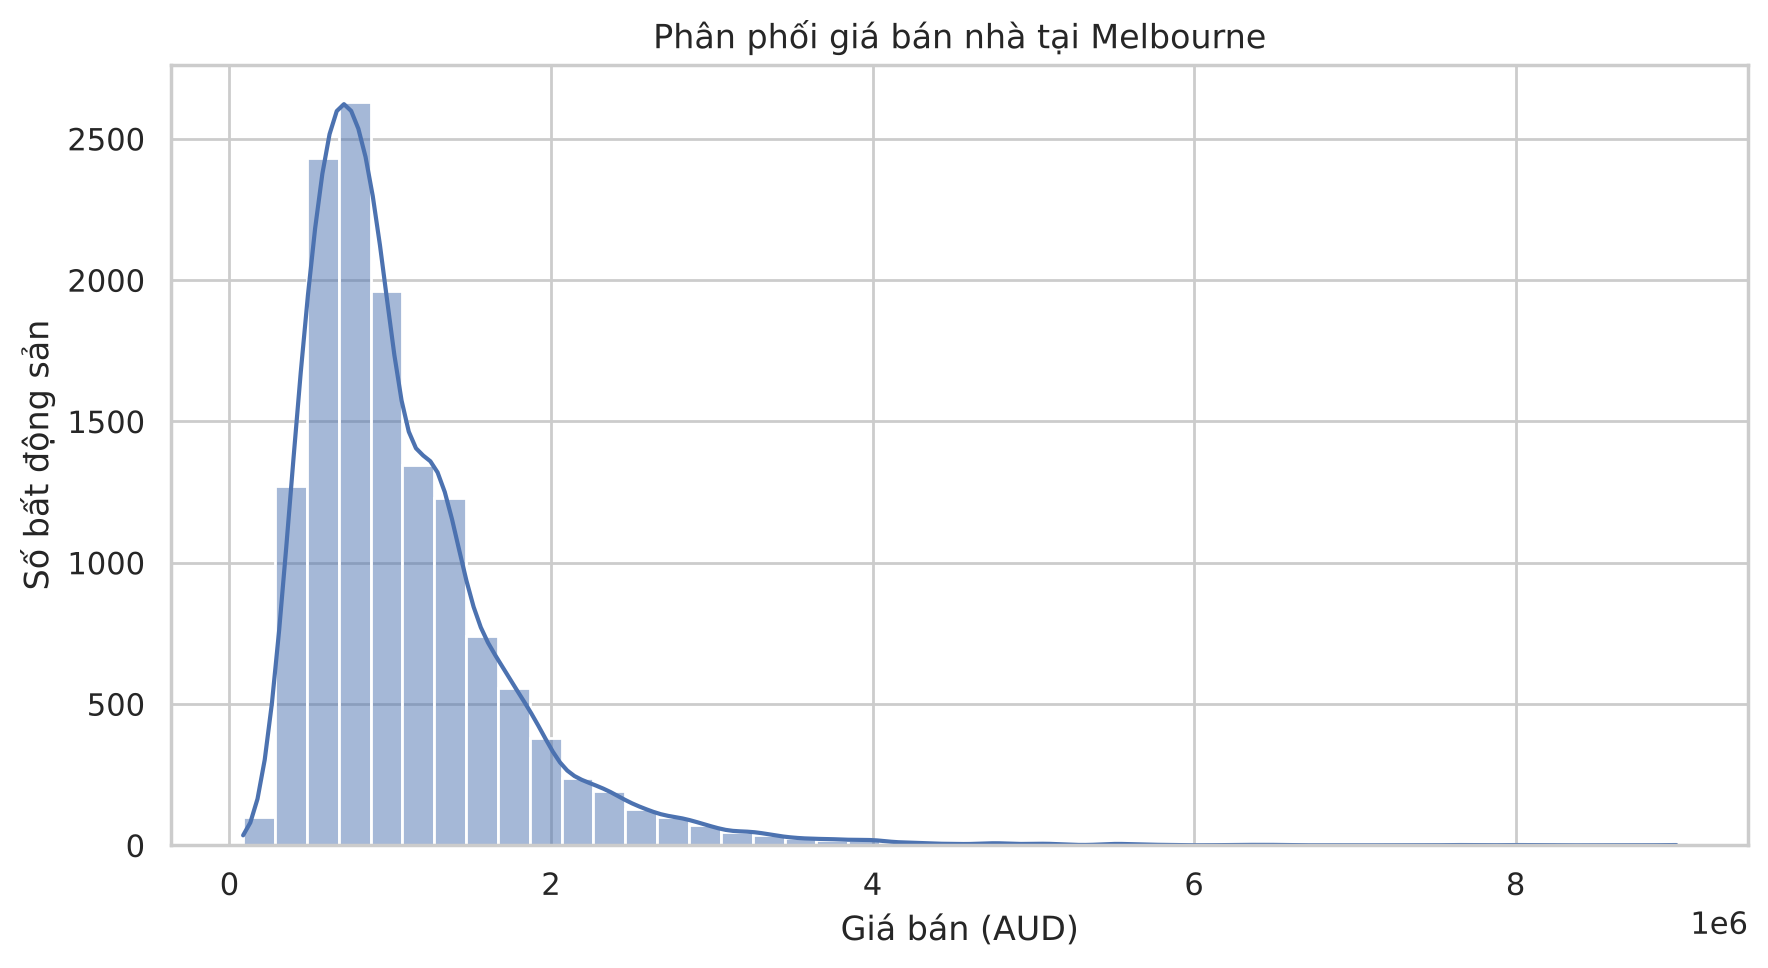

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_clean["Price"].dropna(), bins=45, kde=True, color=sns.color_palette()[0], ax=ax)
ax.set(title="Phân phối giá bán nhà tại Melbourne", xlabel="Giá bán (AUD)", ylabel="Số bất động sản")
plt.tight_layout()
plt.show()

## 13. Trực quan hóa 2 — Boxplot giá theo loại bất động sản

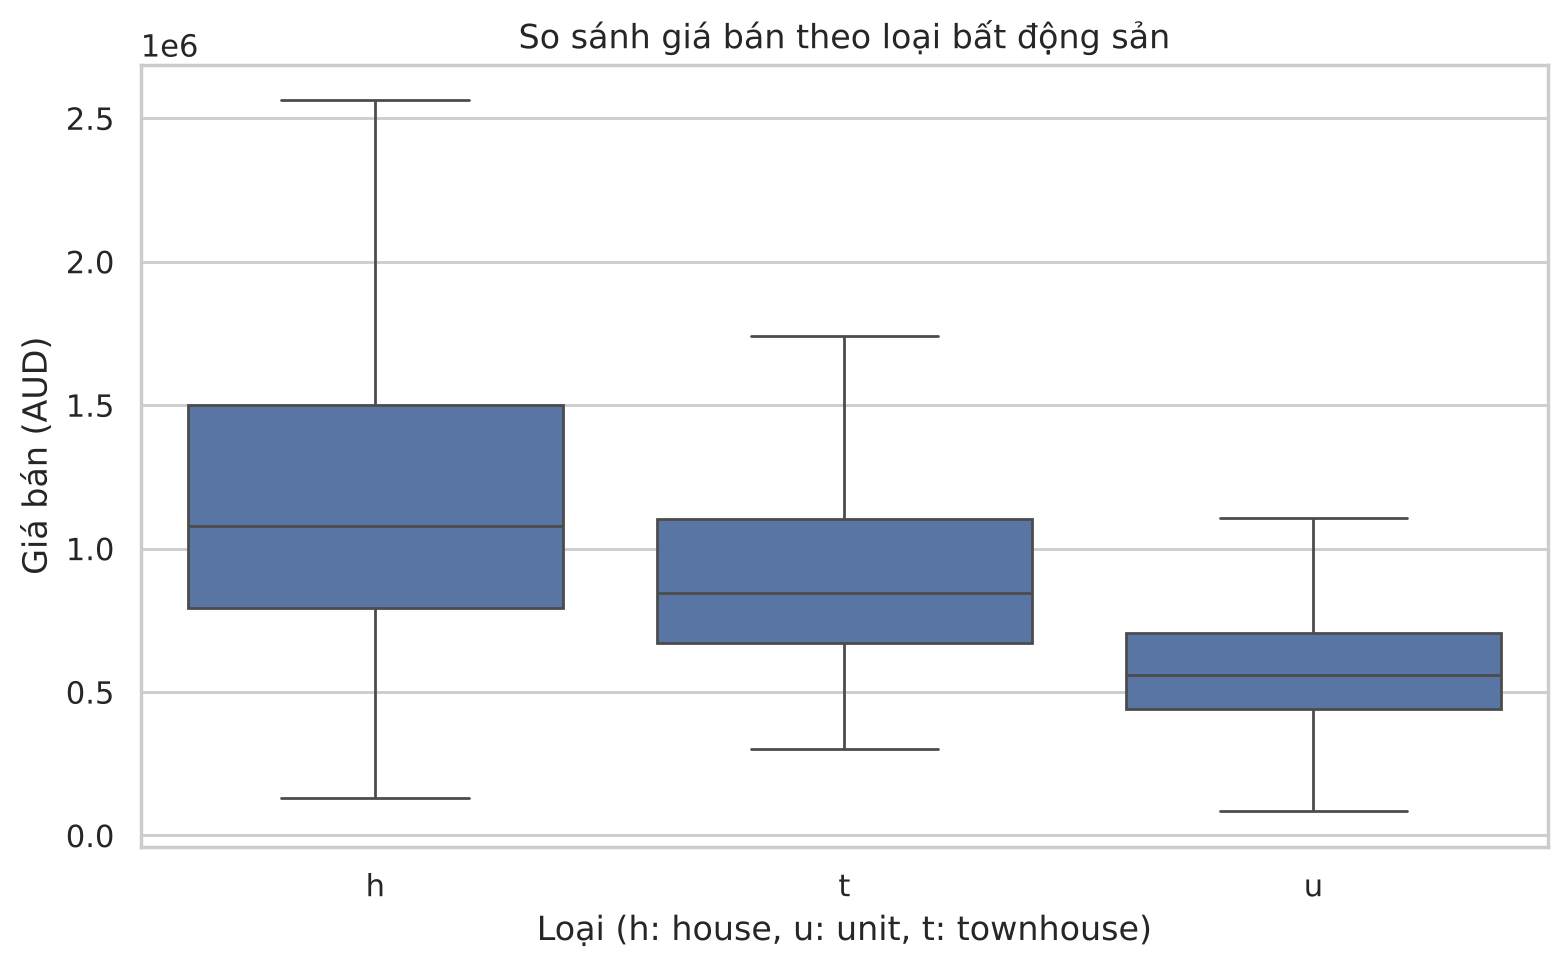

In [17]:
order_type = df_clean.groupby("Type")["Price"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Type", y="Price", order=order_type, showfliers=False, color=sns.color_palette()[0], ax=ax)
ax.set(title="So sánh giá bán theo loại bất động sản", xlabel="Loại (h: house, u: unit, t: townhouse)", ylabel="Giá bán (AUD)")
plt.tight_layout()
plt.show()

## 14. Trực quan hóa 3 — Bar chart giá trung vị theo vùng

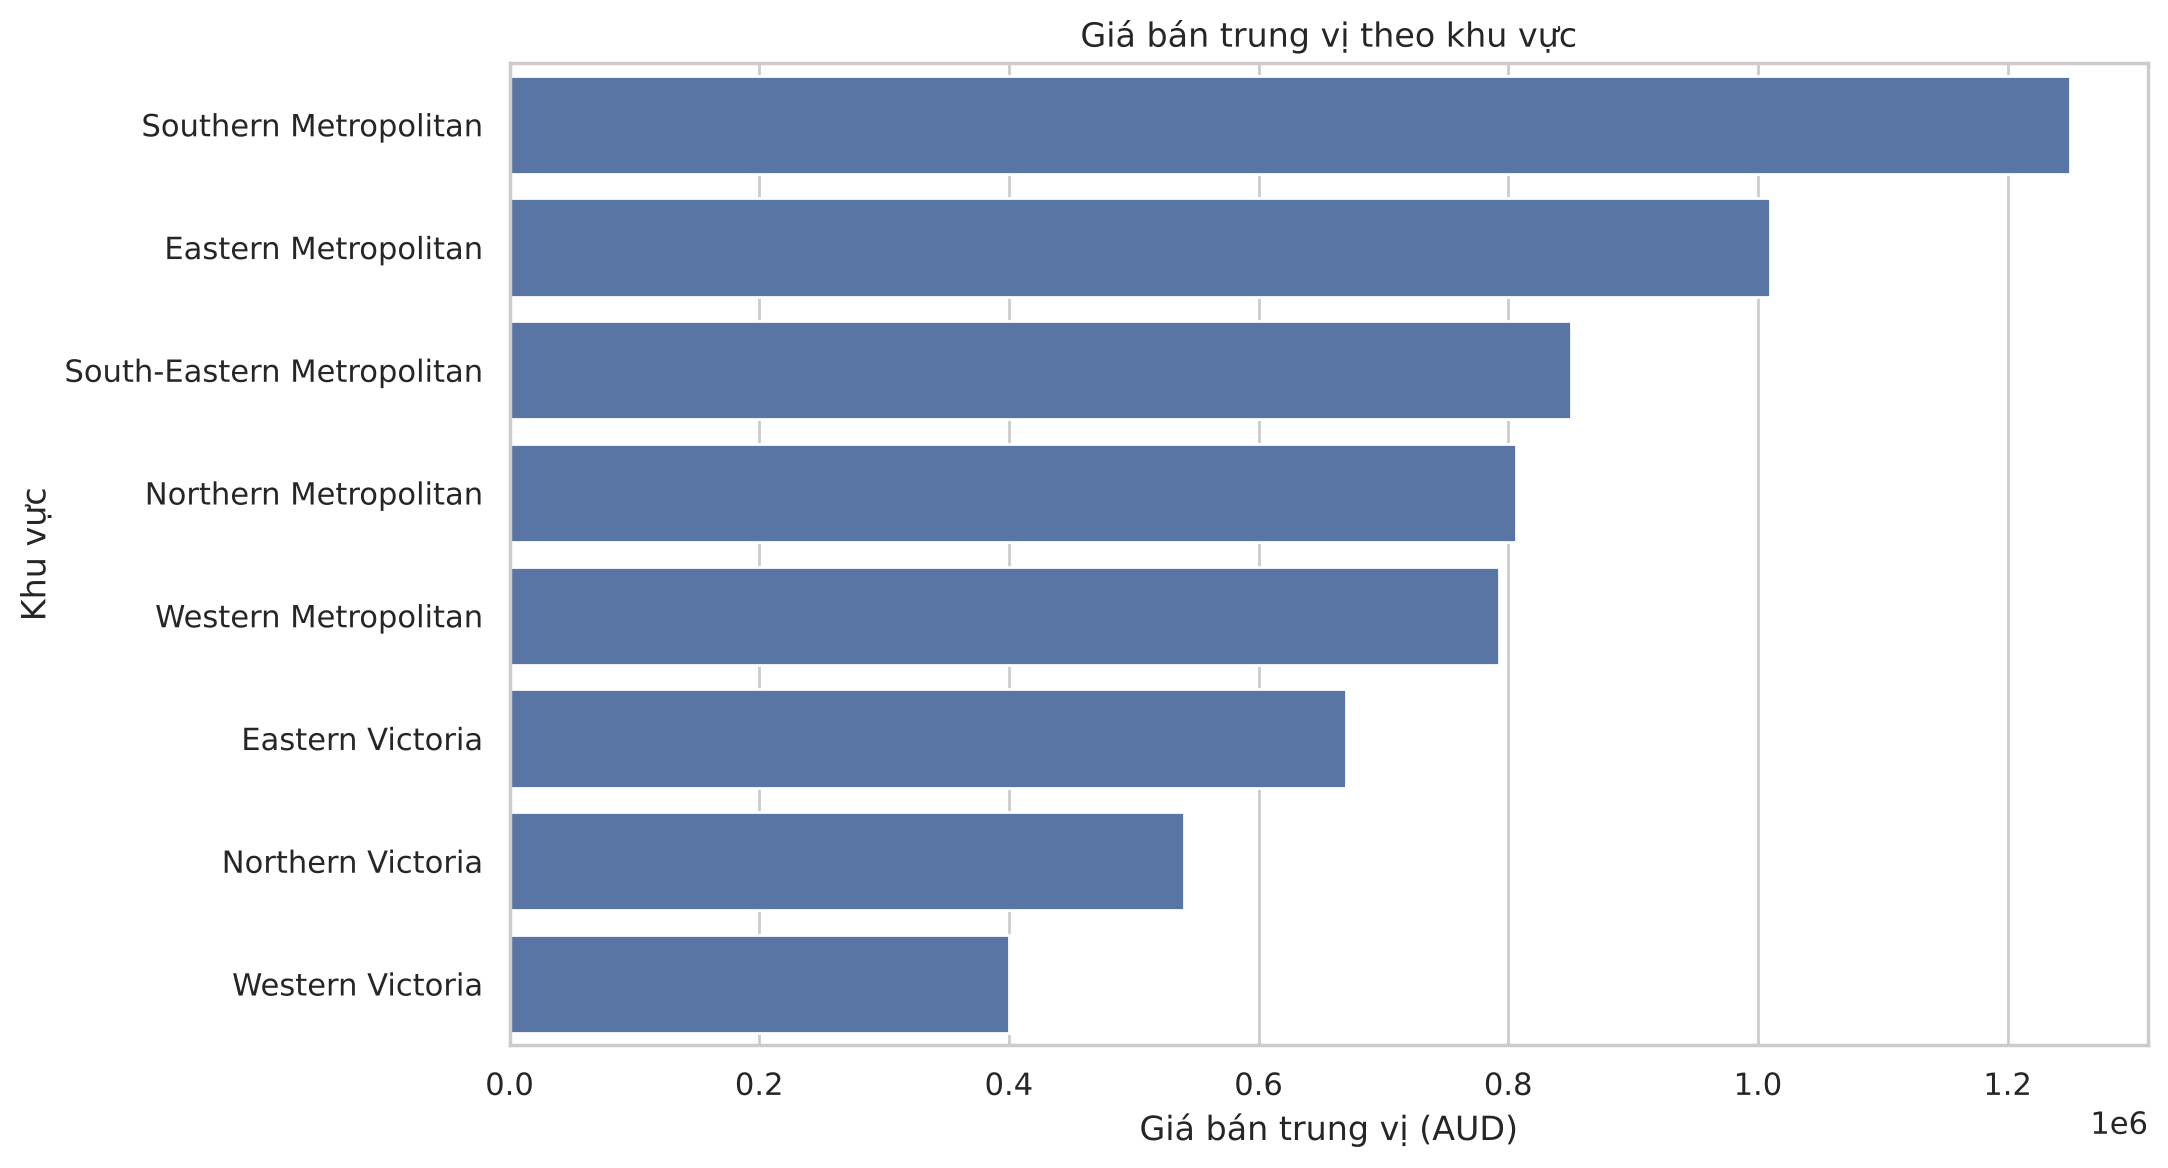

In [18]:
region_median = df_clean.groupby("Regionname")["Price"].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=region_median.values, y=region_median.index, color=sns.color_palette()[0], ax=ax)
ax.set(title="Giá bán trung vị theo khu vực", xlabel="Giá bán trung vị (AUD)", ylabel="Khu vực")
plt.tight_layout()
plt.show()

## 15. Trực quan hóa 4 — Scatter plot khoảng cách đến CBD và giá

Mẫu tối đa 4.000 điểm được hiển thị để biểu đồ dễ đọc; toàn bộ dữ liệu vẫn được dùng khi tính toán thống kê.

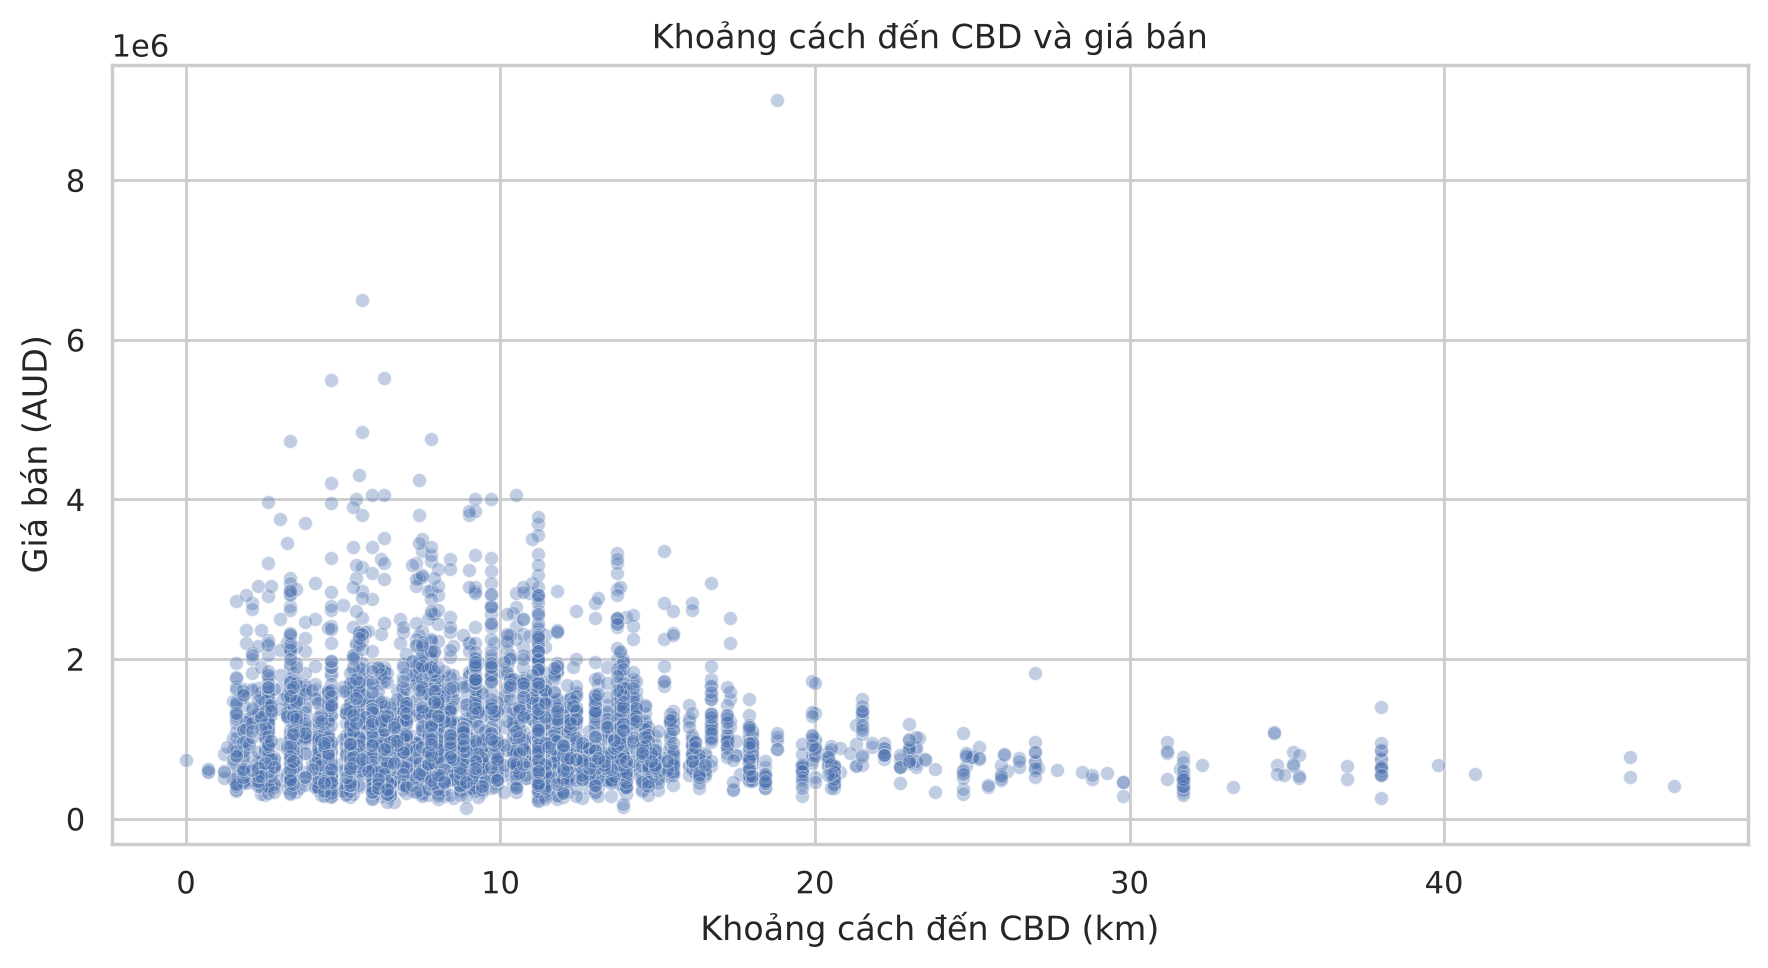

In [19]:
scatter_df = df_clean[["Distance", "Price"]].dropna()
if len(scatter_df) > 4000:
    scatter_df = scatter_df.sample(4000, random_state=42)
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=scatter_df, x="Distance", y="Price", alpha=0.35, s=25, color=sns.color_palette()[0], ax=ax)
ax.set(title="Khoảng cách đến CBD và giá bán", xlabel="Khoảng cách đến CBD (km)", ylabel="Giá bán (AUD)")
plt.tight_layout()
plt.show()

## 16. Trực quan hóa 5 — Heatmap tương quan

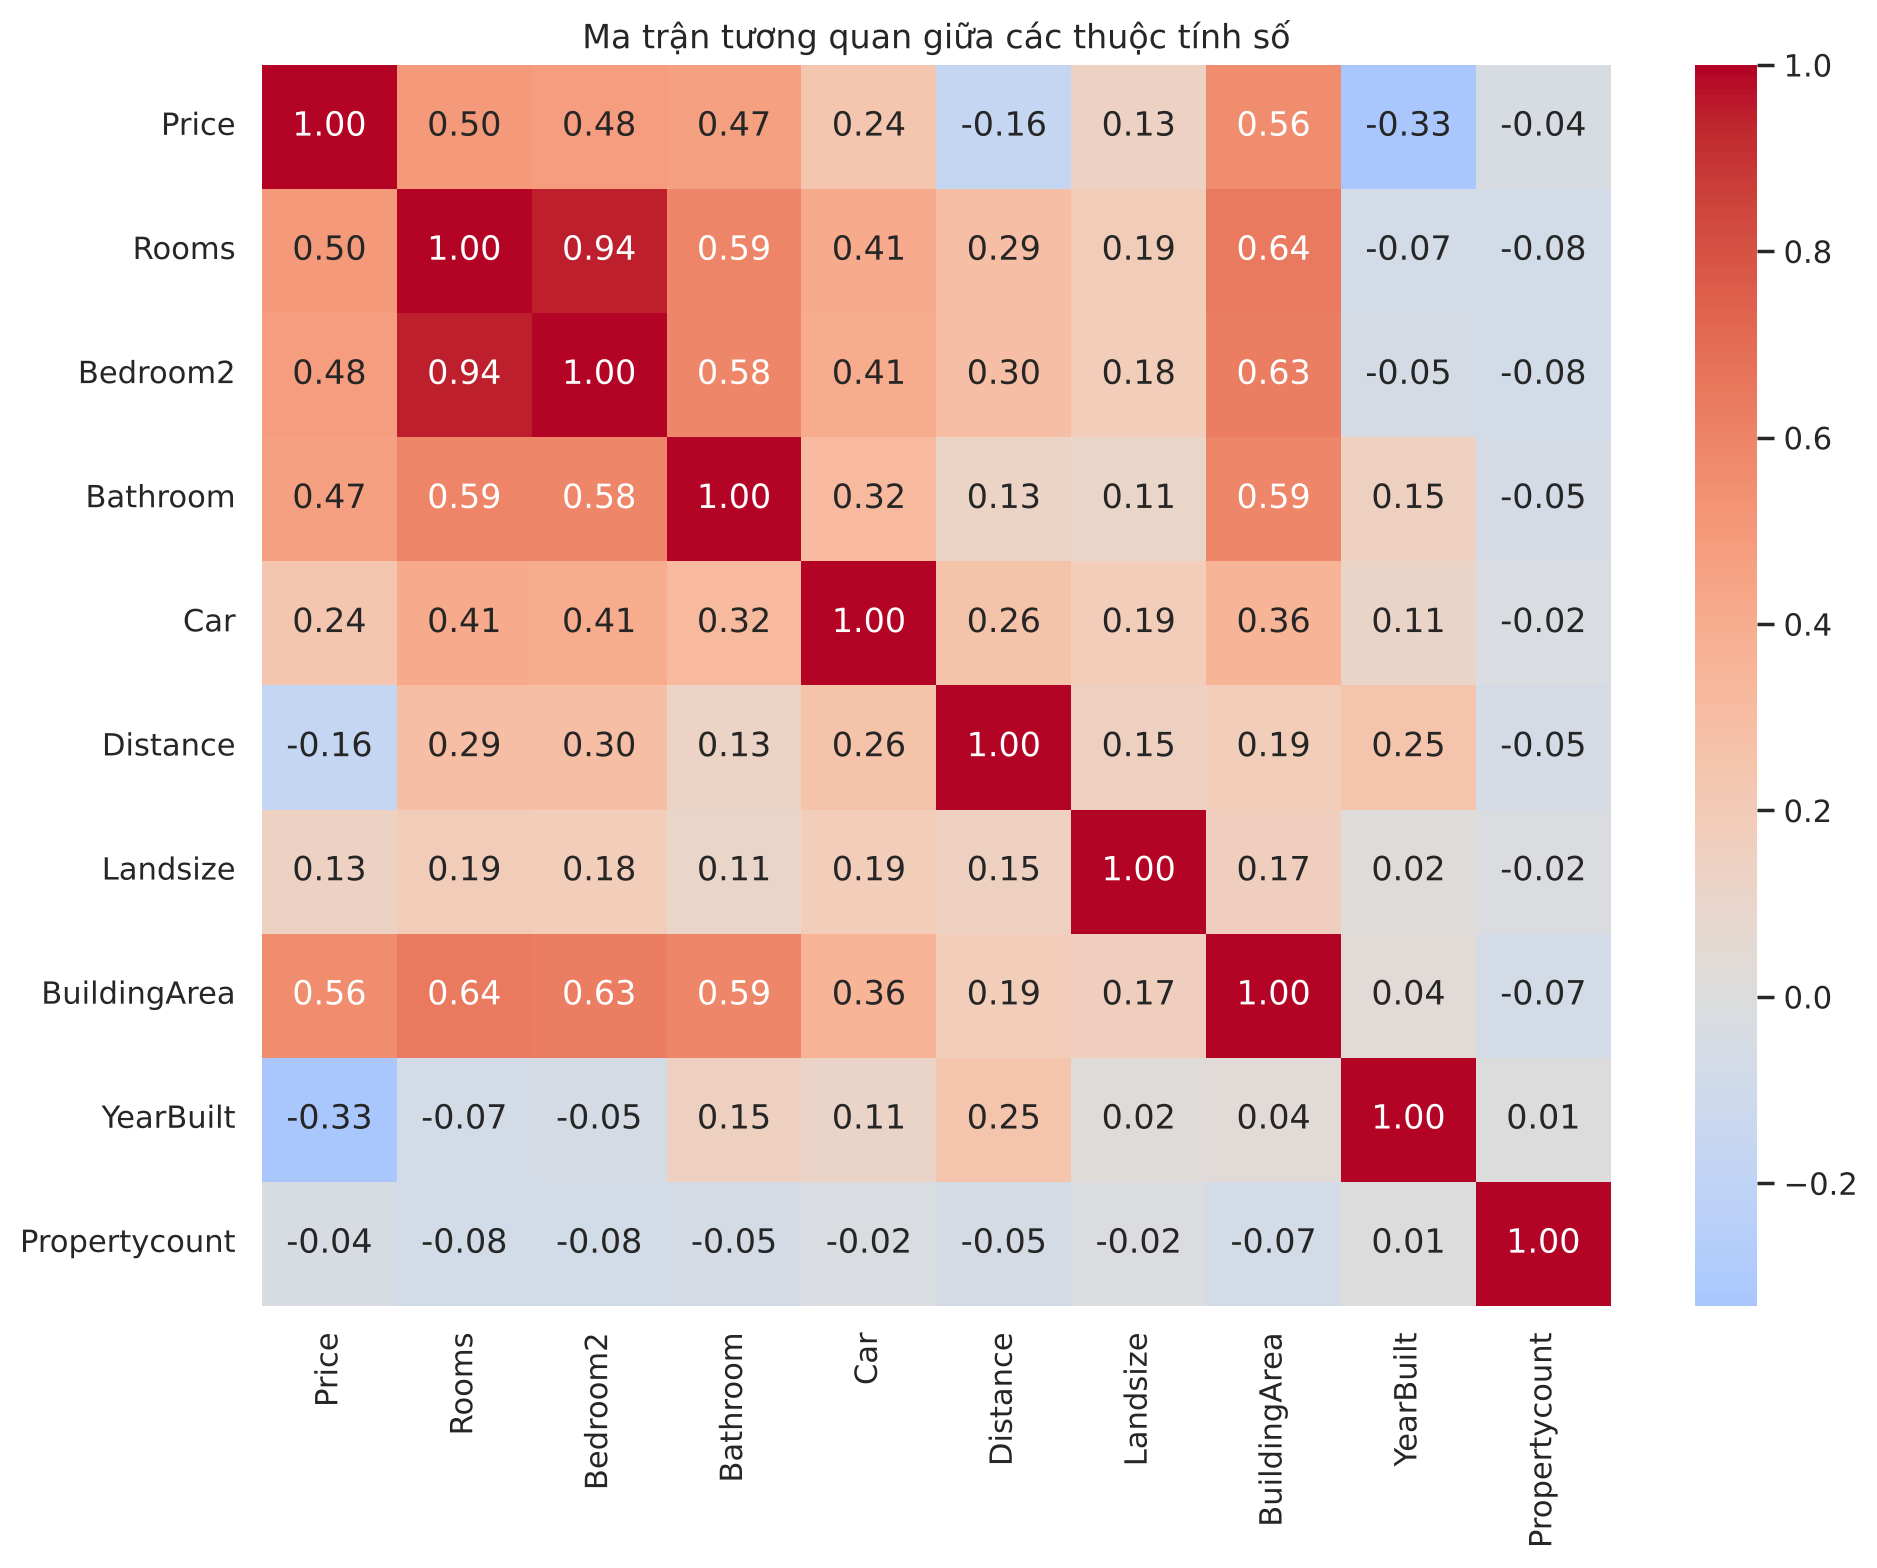

In [20]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Ma trận tương quan giữa các thuộc tính số")
plt.tight_layout()
plt.show()

## 17. Tự động sinh nhận xét từ dữ liệu

Các nhận xét được tính từ `df_clean`, vì vậy sẽ cập nhật nếu dataset được thay đổi. Khi viết báo cáo, hãy giải thích ý nghĩa và nêu giới hạn của mỗi nhận xét, không chỉ chép số liệu.

In [ ]:
findings = []

median_by_type = df_clean.groupby("Type")["Price"].median().dropna().sort_values(ascending=False)
if len(median_by_type) ≥ 2:
    high_type, low_type = median_by_type.index[0], median_by_type.index[-1]
    ratio = median_by_type.iloc[0] / median_by_type.iloc[-1]
    findings.append(
        f"Loại {high_type} có giá trung vị cao nhất ({median_by_type.iloc[0]:,.0f} AUD), "
        f"trong khi loại {low_type} thấp nhất ({median_by_type.iloc[-1]:,.0f} AUD); "
        f"chênh lệch trung vị khoảng {ratio:.2f} lần."
    )

region_stats = df_clean.groupby("Regionname")["Price"].agg(["count", "median"])
region_stats = region_stats[region_stats["count"] ≥ 30].sort_values("median", ascending=False)
if len(region_stats) ≥ 2:
    findings.append(
        f"Trong các khu vực có ít nhất 30 bản ghi, {region_stats.index[0]} có giá trung vị cao nhất "
        f"({region_stats.iloc[0]['median']:,.0f} AUD), còn {region_stats.index[-1]} thấp nhất "
        f"({region_stats.iloc[-1]['median']:,.0f} AUD)."
    )

corr_rooms = df_clean["Price"].corr(df_clean["Rooms"])
corr_distance = df_clean["Price"].corr(df_clean["Distance"])
findings.append(
    f"Tương quan Pearson giữa Price và Rooms là {corr_rooms:.2f}; trong snapshot này, hai biến có liên hệ tuyến tính dương, "
    "nhưng điều đó không chứng minh số phòng là nguyên nhân duy nhất làm giá tăng."
)
findings.append(
    f"Tương quan Pearson giữa Price và Distance là {corr_distance:.2f}; liên hệ tuyến tính với khoảng cách đến CBD "
    "yếu hơn liên hệ với số phòng trong tập dữ liệu này."
)

missing_area = df_clean["BuildingArea"].isna().mean() * 100
missing_year = df_clean["YearBuilt"].isna().mean() * 100
findings.append(
    f"BuildingArea còn thiếu {missing_area:.1f}% và YearBuilt còn thiếu {missing_year:.1f}% sau khi làm sạch; "
    "cần cân nhắc cẩn thận trước khi dùng hai cột này trong mô hình hoặc thống kê."
)

for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

with (OUTPUT_DIR / "findings.txt").open("w", encoding="utf-8") as f:
    f.write("\n".join(f"{i}. {finding}" for i, finding in enumerate(findings, start=1)))
print("\nĐã lưu nhận xét vào:", OUTPUT_DIR / "findings.txt")

1. Loại h có giá trung vị cao nhất (1,080,000 AUD), trong khi loại u thấp nhất (560,000 AUD); chênh lệch trung vị khoảng 1.93 lần.
2. Trong các khu vực có ít nhất 30 bản ghi, Southern Metropolitan có giá trung vị cao nhất (1,250,000 AUD), còn Western Victoria thấp nhất (400,000 AUD).
3. Tương quan Pearson giữa Price và Rooms là 0.50; trong snapshot này, hai biến có liên hệ tuyến tính dương, nhưng điều đó không chứng minh số phòng là nguyên nhân duy nhất làm giá tăng.
4. Tương quan Pearson giữa Price và Distance là -0.16; liên hệ tuyến tính với khoảng cách đến CBD yếu hơn liên hệ với số phòng trong tập dữ liệu này.
5. BuildingArea còn thiếu 47.7% và YearBuilt còn thiếu 39.6% sau khi làm sạch; cần cân nhắc cẩn thận trước khi dùng hai cột này trong mô hình hoặc thống kê.

Đã lưu nhận xét vào: /home/claude/2611comp1804-laptrinhpython-doangk/outputs/findings.txt


## 18. Kết luận và giới hạn

- Đã đáp ứng quy mô tối thiểu: trên 500 bản ghi và trên 5 thuộc tính.
- Có mô tả nguồn, đọc dữ liệu bằng Pandas, kiểm tra kiểu dữ liệu, dữ liệu thiếu/trùng/không hợp lý và làm sạch có giải thích.
- Có ít nhất 5 phép phân tích dùng `groupby`, lọc, sắp xếp hoặc tổng hợp; có 5 biểu đồ thuộc nhiều loại khác nhau.
- Các nhận xét là mô tả trong snapshot lịch sử của Melbourne giai đoạn 2016–2017. Không suy rộng thành giá thị trường hiện tại hoặc thị trường Việt Nam.
- `BuildingArea` và `YearBuilt` còn thiếu nhiều dữ liệu. Mô hình Regression trong `train_model.py` điền giá trị thiếu bên trong `Pipeline`, chỉ học từ tập train, để tránh rò rỉ dữ liệu giữa train/validation/test.
- Các giá trị ngoài IQR không tự động xóa. Cần xem ngữ cảnh để quyết định là lỗi nhập liệu hay giao dịch đặc biệt. Các giá trị diện tích phi thực tế (`Landsize` > 10.000 m²: 26 dòng; `BuildingArea` > 1.000 m²: 8 dòng) và 34 dòng `Bathroom == 0` đã được đặt thành thiếu; nhờ vậy Pearson của `BuildingArea` với giá tăng từ 0,09 lên 0,56.

### Có thể phát triển tiếp

1. Phân tích sâu theo thời gian hoặc bản đồ tọa độ.
2. Cải thiện mô hình Regression trong `train_model.py`: chia tập theo thời gian, thử loại `Method` và tinh chỉnh siêu tham số.